In [1]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from IPython.display import display

FILE = r"C:\Users\K Ganesh\Documents\Ocean Dynamics\IMD_Best_Tracks_Data_1982-2025 (1).xlsx"
INTERVAL_DAYS = 4

In [2]:
excel = pd.ExcelFile(FILE)

if "2014" not in excel.sheet_names:
    raise ValueError(f"No 2014 sheet found. Sheets include: {excel.sheet_names}")

df = pd.read_excel(FILE, sheet_name="2014")
df.columns = [str(column).strip() for column in df.columns]

print("2014 sheet columns:")
print(df.columns.tolist())

2014 sheet columns:
['Serial Number of system during year', 'Basin of origin', 'Name', 'Date(DD-MM-YYYY)', 'Time (UTC)', 'Latitude (lat)', 'longitude  (Long)', 'CI No [or "T. No"]', 'Estimated Central Pressure (hPa) [or "E.C.P"]', 'Maximum Sustained Surface Wind (kt)', 'Pressure Drop (hPa)[or "delta P"]', 'Grade (text)', 'Outermost closed isobar (hPa)', 'Diameter/Size of outermost closed isobar(in degree)']


In [4]:

name_column = next(
    (
        column for column in df.columns
        if str(column).strip().lower() == "name"
    ),
    None
)

if name_column is None:
    raise ValueError(f"Could not find the cyclone name column. Found: {df.columns.tolist()}")


date_column = next(
    (
        column for column in df.columns
        if str(column).strip().lower() == "date"
        or str(column).strip().lower().startswith("date(")
    ),
    None
)

if date_column is None:
    raise ValueError(f"Could not find the date column. Found: {df.columns.tolist()}")


def normalize_heading(text):
    return "".join(character for character in str(text).lower() if character.isalnum())

normalized_columns = {
    normalize_heading(column): column
    for column in df.columns
}

latitude_column = next(
    (
        original for normalized, original in normalized_columns.items()
        if normalized.startswith("latitude")
    ),
    None
)

longitude_column = next(
    (
        original for normalized, original in normalized_columns.items()
        if normalized.startswith("longitude")
    ),
    None
)

if latitude_column is None or longitude_column is None:
    raise ValueError(
        "Could not identify latitude and longitude columns. "
        f"Columns found: {df.columns.tolist()}"
    )

print("Name column:", name_column)
print("Date column:", date_column)
print("Latitude column:", latitude_column)
print("Longitude column:", longitude_column)

Name column: Name
Date column: Date(DD-MM-YYYY)
Latitude column: Latitude (lat)
Longitude column: longitude  (Long)


In [5]:

hudhud = df[
    df[name_column].astype(str).str.strip().str.upper().eq("HUDHUD")
].copy()

if hudhud.empty:
    raise ValueError(
        "No rows named HUDHUD were found in the 2014 sheet. "
        "Check the Name column values."
    )

# Convert dates and coordinates
hudhud["Date"] = pd.to_datetime(
    hudhud[date_column],
    dayfirst=True,
    errors="coerce"
)

hudhud["Latitude"] = pd.to_numeric(
    hudhud[latitude_column],
    errors="coerce"
)

hudhud["Longitude"] = pd.to_numeric(
    hudhud[longitude_column],
    errors="coerce"
)


wind_column = next(
    (
        column for column in hudhud.columns
        if "maximum sustained surface wind" in str(column).lower()
    ),
    None
)

grade_column = next(
    (
        column for column in hudhud.columns
        if str(column).strip().lower() == "grade (text)"
    ),
    None
)

if wind_column is not None:
    hudhud["Wind_kt"] = pd.to_numeric(hudhud[wind_column], errors="coerce")

if grade_column is not None:
    hudhud["Grade"] = hudhud[grade_column]


hudhud = (
    hudhud
    .dropna(subset=["Date", "Latitude", "Longitude"])
    .sort_values("Date")
    .reset_index(drop=True)
)

if hudhud.empty:
    raise ValueError("Hudhud was found, but no rows had valid dates and coordinates.")

print("Hudhud observations:", len(hudhud))
print("Track dates:", hudhud["Date"].min(), "to", hudhud["Date"].max())

Hudhud observations: 53
Track dates: 2014-10-07 00:00:00 to 2014-10-14 00:00:00


In [6]:
start_date = hudhud["Date"].min()
end_date = hudhud["Date"].max()

target_dates = list(
    pd.date_range(
        start=start_date,
        end=end_date,
        freq=f"{INTERVAL_DAYS}D"
    )
)


target_dates.append(end_date)

selected_rows = []

for target_date in target_dates:
    nearest_index = (hudhud["Date"] - target_date).abs().idxmin()
    selected_rows.append(hudhud.loc[nearest_index])

interval_points = (
    pd.DataFrame(selected_rows)
    .drop_duplicates(subset=["Date"])
    .sort_values("Date")
    .reset_index(drop=True)
)


table_columns = ["Date", "Latitude", "Longitude"]

if "Wind_kt" in interval_points.columns:
    table_columns.append("Wind_kt")

if "Grade" in interval_points.columns:
    table_columns.append("Grade")

display(interval_points[table_columns].round(2))

C:\Users\K Ganesh\AppData\Local\Temp\ipykernel_40308\4201794678.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(interval_points[table_columns].round(2))


,Date,Latitude,Longitude,Wind_kt,Grade
0,2014-10-07,11.5,95.0,25.0,D
1,2014-10-11,15.9,85.7,75.0,VSCS
2,2014-10-14,25.6,81.7,20.0,D


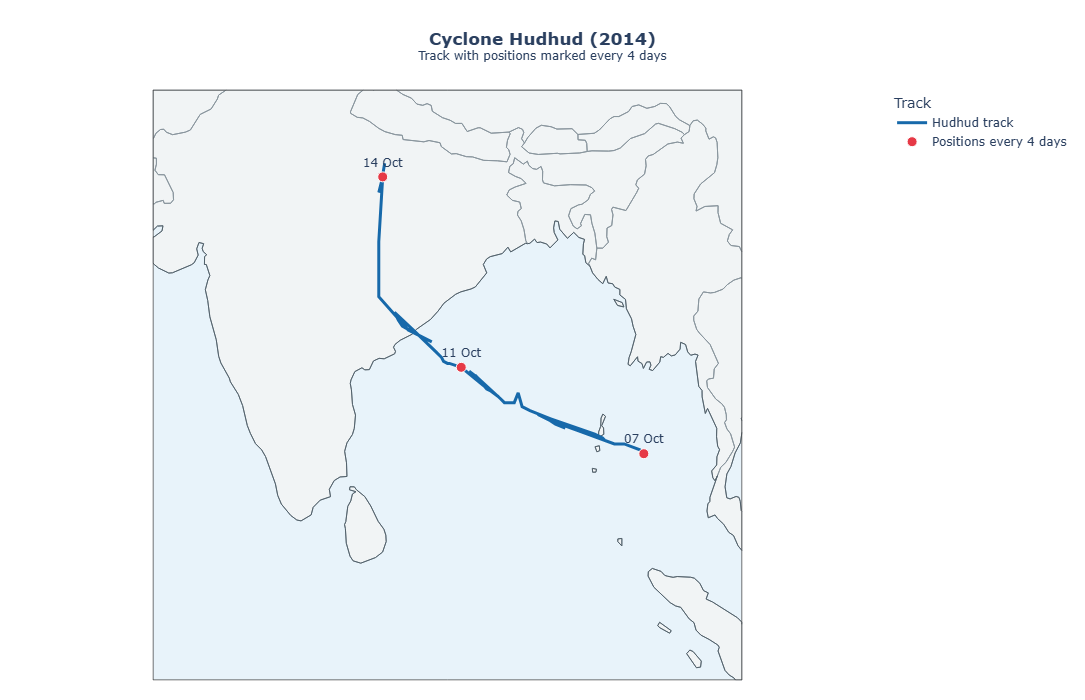

In [7]:
fig = go.Figure()


fig.add_trace(go.Scattergeo(
    lat=hudhud["Latitude"],
    lon=hudhud["Longitude"],
    mode="lines",
    line=dict(width=3, color="#1769aa"),
    name="Hudhud track",
    text=hudhud["Date"].dt.strftime("%d %b %Y"),
    hovertemplate=(
        "Date: %{text}<br>"
        "Latitude: %{lat:.2f}°<br>"
        "Longitude: %{lon:.2f}°"
        "<extra>Hudhud</extra>"
    )
))


fig.add_trace(go.Scattergeo(
    lat=interval_points["Latitude"],
    lon=interval_points["Longitude"],
    mode="markers+text",
    text=interval_points["Date"].dt.strftime("%d %b"),
    textposition="top center",
    marker=dict(
        size=10,
        color="#e63946",
        line=dict(width=1, color="white")
    ),
    name=f"Positions every {INTERVAL_DAYS} days",
    hovertemplate=(
        "Date: %{text}<br>"
        "Latitude: %{lat:.2f}°<br>"
        "Longitude: %{lon:.2f}°"
        "<extra>Interval position</extra>"
    )
))

fig.update_geos(
    showcountries=True,
    countrycolor="#8a969e",
    showcoastlines=True,
    coastlinecolor="#52616b",
    showland=True,
    landcolor="#f1f4f5",
    showocean=True,
    oceancolor="#e8f3fa",
    lataxis_range=[0, 30],
    lonaxis_range=[70, 100]
)

fig.update_layout(
    title=dict(
        text="<b>Cyclone Hudhud (2014)</b><br><sup>Track with positions marked every 4 days</sup>",
        x=0.5,
        xanchor="center"
    ),
    height=700,
    legend_title_text="Track",
    margin=dict(l=20, r=20, t=90, b=20)
)

fig.show()